# **AI METHODS I**
----
## Step I: Data cleaning and Exploratory Data Analysis (EDA)

### Goals

1. Load the dataset ""global_city_col_qol_index.csv"" from Kaggle directly into **pandas**.

    Steps:    
    a. Choose a python environment    
    b. Set up / Install packages with **.pip** and **import as**                
    c. Set up folders with realitve paths so they can work in any computer     
    d. Import CSV file with **.read()**      
          
2. Inspect the dataset and write a short **dataset card** (source, content, limitations).        

    Steps:    
    a. **.shape** | Number of rows and columns     
    b. **.head()** | The first rows: what the values look like                  
    c. **.info()** | Column names, data types and how many values are *not* missing |   
    d. **.describe()** | Summary statistics (mean, min, max, quartiles…) 
      
3. Detect and fix the classic **data problems**:       
           
    Steps:     
    a. Make a copy of de dataframe with **.copy()**     
    b. Tidy columns names if it's necessary     
    c. Remove all duplicated values with **.duplicated()**       
    d. Get an overview of **missing values()**  
    e. Remove irrelevant columns with **drop.()**    
    f. Fix inconsistent data types and outliers.           


4. **Feature Engineering** 
     
    Steps:     
    a. Extract **temporal features** (If necessary)  
    b. **Create** more features depending on the **relation between existing features**.              
    c. Format or transform variables to ensure they are fully model-ready   

5. **Comparing** raw and clean data sets

6. **(EDA)** Exploring the data with **descriptive statistics** and **visualizations** (matplotlib + seaborn).

    Steps:      
    a.  **Univariate**: one variable at a time    
    b.  **Bivariate**: two variables together       
    c. **Multivariate**: several variables at once      

7. Save a clean, **model-ready dataset** 

----
## 1. Loading the Dataset

Steps:    
    a. Choose a python environmen    
    b. Set up / Install packages with **.pip** and **import as**                
    c. Set up folders with realitve paths so they can work in any computer     
    d. Import CSV file with **.read()**

### a. Choose a python environmen

In [1]:
# Choose python environment. If doesn't work use this --->>   
# (1) python -m venv .venv 
# (2) .venv\Scripts\Activate.ps1

### b. Set up / Install packages with **.pip** and **import as**    

In [2]:
# Set-up/ install packages.
%pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Import installed packages/ libraries into environment?
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path

### c. Set up folders with realitve paths so they can work in any computer and save images as png

In [4]:
# Set-up folders --- data and figures --- relative paths to enable the notebook to work on any computer.

DATA_DIR = Path("data")      # raw and clean CSV files go here
FIG_DIR = Path("figures")    # exported plots go here

DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)

In [5]:
# pandas display options 
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# plot style 
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 42

In [6]:
# "save_fig()" exports plots as .png 
# Creating a function to call when we need to save a figure (plot during analysis) onto the computer.

def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

### d. Import CSV file with **.read()**

In [7]:
# Import csv file from data folder.
df = pd.read_csv(
    DATA_DIR / "global_city_col_qol_index.csv"
)

# print info of imported csv data --- check
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")

Loaded 296 rows and 26 columns


# 2. Inspect de dataset

Steps:    
    a. **.shape** | Number of rows and columns     
    b. **.head()** | The first rows: what the values look like                  
    c. **.info()** | Column names, data types and how many values are *not* missing    
    d. **.describe()** | Summary statistics (mean, min, max, quartiles…) 

### Dataset card

| | |
|---|---|
| **Name** | Global City Cost of Living & Quality of Life Index |
| **Source** | Kaggle, [Chaitanya Jamble](https://www.kaggle.com/datasets/chaitanyajamble/global-city-cost-of-living-and-quality-of-life-index) |
| **Origin** |Each city is anchored to the World Bank/IMF public data  |
| **Unit of observation** | Two rows = one **country** of a list of 148 |
| **Size (raw)** | 296 rows × 26 columns |
| **Target for Day 2** | `quality_of_life_index` (or `qol_category`): overall quality of life score/category for each city |
| **Licence** | Check the *License* field on the Kaggle page before re-using the data in a publication |
| **Known limitations** | Contains synthetic patterns, some columns have missing values (e.g., net salary, traffic, climate), and each city appears twice across different years |

### a. **.shape** | Number of rows and columns  

In [8]:
# Use shape to see number of rows and columns
df.shape

(296, 26)

### b. **.head()** | The first rows: what the values look like    

In [9]:
# The first 5 rows.
df.head()

,city_id,city,country,region,subregion,development_tier,population_millions,currency_code,survey_date,cost_of_living_index,rent_index,groceries_index,restaurant_price_index,local_purchasing_power_index,avg_monthly_net_salary_usd,housing_price_to_income_ratio,health_care_index,safety_index,pollution_index,traffic_commute_index,climate_index,internet_speed_mbps,quality_of_life_index,qol_category,data_source_pattern,analyst_note
0,112,Abidjan,Cote d'Ivoire,Africa,Western Africa,4,4.89,XOF,2023-06-15,43.29,24.06,43.18,46.49,38.45,"1,650.87",18.48,29.59,49.52,86.13,61.74,85.79,38.10,42.92,Medium,Synthetic-Numbeo-pattern,NaN
1,112,Abidjan,Cote d'Ivoire,Africa,Western Africa,4,4.89,XOF,2024-06-15,51.53,26.11,47.59,46.68,43.25,"1,826.78",20.84,22.86,49.85,86.33,63.21,63.07,47.30,32.57,Low,Synthetic-EIU-pattern,New infrastructure projects may improve traffi...
2,76,Abu Dhabi,United Arab Emirates,Asia,Western Asia,1,3.22,AED,2023-06-15,100.39,61.19,86.04,64.62,111.37,"6,040.30",8.82,96.34,94.67,38.15,32.22,83.63,168.40,82.84,Very High,Synthetic-EIU-pattern,NaN
3,76,Abu Dhabi,United Arab Emirates,Asia,Western Asia,1,3.22,AED,2024-06-15,95.65,78.33,98.88,84.45,109.32,"6,363.54",10.11,89.47,56.12,28.94,29.20,31.57,NaN,59.92,High,Synthetic-Mercer-pattern,NaN
4,99,Abuja,Nigeria,Africa,Western Africa,4,2.64,NGN,2023-06-15,46.82,32.79,29.90,39.25,49.86,"2,186.81",18.82,38.37,47.52,78.13,65.04,58.49,81.90,38.86,Medium,Synthetic-EIU-pattern,Cost gap between city center and suburbs is wi...


### c. **.info()** | Column names, data types and how many values are *not* missing

In [10]:
# Column names, data types (Dtype) and number of non-missing values per column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 296 entries, 0 to 295
Data columns (total 26 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   city_id                        296 non-null    int64  
 1   city                           296 non-null    object 
 2   country                        296 non-null    object 
 3   region                         296 non-null    object 
 4   subregion                      296 non-null    object 
 5   development_tier               296 non-null    int64  
 6   population_millions            296 non-null    float64
 7   currency_code                  296 non-null    object 
 8   survey_date                    296 non-null    object 
 9   cost_of_living_index           296 non-null    float64
 10  rent_index                     296 non-null    float64
 11  groceries_index                296 non-null    float64
 12  restaurant_price_index         296 non-null    flo

### d. **.describe()** | Summary statistics (mean, min, max, quartiles…)

In [11]:
# .T transposes the table (rows <-> columns) so it is easier to read with many columns
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
city_id,296.00,NaN,NaN,NaN,74.50,42.80,1.00,37.75,74.50,111.25,148.00
city,296,148,Abidjan,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,296,92,United States,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,296,5,Europe,92,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subregion,296,17,Northern America,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
development_tier,296.00,NaN,NaN,NaN,2.26,1.13,1.00,1.00,2.00,3.00,4.00
population_millions,296.00,NaN,NaN,NaN,5.10,6.00,0.31,1.94,3.13,5.60,38.00
currency_code,296,75,EUR,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
survey_date,296,2,2023-06-15,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cost_of_living_index,296.00,NaN,NaN,NaN,75.16,22.31,23.54,58.85,76.97,94.70,113.29


# 3. Detect and fix the classic data problems:       
           
Steps:     
    a. Make a copy of de dataframe with **.copy()**     
    b. Tidy columns names if it's necessary     
    c. Remove all duplicated values with **.duplicated()**       
    d. Get an overview of **missing values()**  
    e. Remove irrelevant columns with **drop.()**    
    f. Fix inconsistent data types and outliers. 

### a. Make a copy of de dataframe with **.copy()**

In [12]:
# .copy() creates an independent copy: changing df_clean will NOT change df
df_clean = df.copy()

### b. Tidy columns names if it's necessary 

In [13]:
# # Give new names to columns if they are not proper.
# new_names = {"Old_Name":"new_name",
#              "Old_Name_2":"new_name_2"}
# df_clean = df_clean.rename(columns=new_names)
# df_clean.columns.tolist()

### c. Remove all duplicated values with **.duplicated()**       


In [14]:
#Check for duplicates rows in the table
n_duplicates = df_clean.duplicated().sum()
print(f"Number of duplicate rows: {n_duplicates}")

Number of duplicate rows: 0


### d. Get an overview of **missing values()**  
   

In [15]:
#check for missing data in the table(n=missing) and percentage of missing data in the table(pct_missing)
def missing_report(data):
    n_missing = data.isnull().sum()
    pct_missing = (n_missing / len(data)) * 100
    report = pd.DataFrame({
        "n_missing": n_missing,
        "pct_missing": pct_missing  
    })
    return report.sort_values(
        "pct_missing", 
        ascending=False
    )
missing = missing_report(df_clean)
missing

,n_missing,pct_missing
analyst_note,193,65.20
internet_speed_mbps,11,3.72
climate_index,11,3.72
traffic_commute_index,11,3.72
housing_price_to_income_ratio,11,3.72
avg_monthly_net_salary_usd,11,3.72
city,0,0.00
data_source_pattern,0,0.00
qol_category,0,0.00
quality_of_life_index,0,0.00


Figure saved to figures\01_missing_values.png


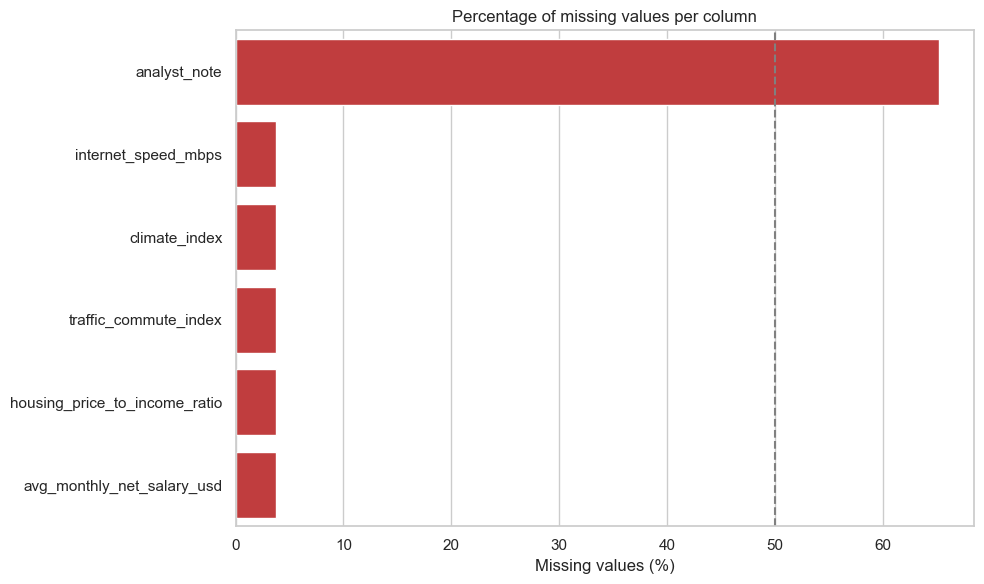

In [16]:
# Easy to understand this with a chart if there is any missing data.
# NONE in this case.

fig, ax = plt.subplots(figsize=(10, 6))

# Only plot the columns that have at least one missing value
missing_to_plot = missing[missing["pct_missing"] > 0]

sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_title("Percentage of missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("01_missing_values")
plt.show()

# Can decide what columns to drop based on this analysis.

In [17]:
# Check missing values before imputation
print("--- Missing values before imputation ---")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

# List of columns with missing values to impute
cols_to_impute = [
    'internet_speed_mbps', 
    'climate_index', 
    'traffic_commute_index', 
    'housing_price_to_income_ratio', 
    'avg_monthly_net_salary_usd'
]

# Fill missing values with the median of each column
for col in cols_to_impute:
    median_value = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_value)

# Verify that no missing values remain in the dataset
print("\n--- Missing values after imputation ---")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

--- Missing values before imputation ---
avg_monthly_net_salary_usd        11
housing_price_to_income_ratio     11
traffic_commute_index             11
climate_index                     11
internet_speed_mbps               11
analyst_note                     193
dtype: int64

--- Missing values after imputation ---
analyst_note    193
dtype: int64


### e. Remove irrelevant columns with **drop.()**    


In [18]:
#column removal because they are not giving us relevant information
columns_to_drop = ["analyst_note",
                   "data_source_pattern"]

df_clean = df_clean.drop(columns=columns_to_drop, errors="ignore")

print(
    f"Remaining columns ({df_clean.shape[1]}): "
    f"{df_clean.columns.tolist()}"
)

Remaining columns (24): ['city_id', 'city', 'country', 'region', 'subregion', 'development_tier', 'population_millions', 'currency_code', 'survey_date', 'cost_of_living_index', 'rent_index', 'groceries_index', 'restaurant_price_index', 'local_purchasing_power_index', 'avg_monthly_net_salary_usd', 'housing_price_to_income_ratio', 'health_care_index', 'safety_index', 'pollution_index', 'traffic_commute_index', 'climate_index', 'internet_speed_mbps', 'quality_of_life_index', 'qol_category']


### f. Fix inconsistent data types

In [19]:
# Convert survey_date to datetime format
df_clean['survey_date'] = pd.to_datetime(df_clean['survey_date'])

# Verify changes
print(df_clean[['survey_date']].dtypes)

survey_date    datetime64[ns]
dtype: object


In [20]:
# Check new dataset scope.

print(f"Reduced data scope: {len(df_clean)}")
df_clean.head()

Reduced data scope: 296


,city_id,city,country,region,subregion,development_tier,population_millions,currency_code,survey_date,cost_of_living_index,rent_index,groceries_index,restaurant_price_index,local_purchasing_power_index,avg_monthly_net_salary_usd,housing_price_to_income_ratio,health_care_index,safety_index,pollution_index,traffic_commute_index,climate_index,internet_speed_mbps,quality_of_life_index,qol_category
0,112,Abidjan,Cote d'Ivoire,Africa,Western Africa,4,4.89,XOF,2023-06-15,43.29,24.06,43.18,46.49,38.45,"1,650.87",18.48,29.59,49.52,86.13,61.74,85.79,38.10,42.92,Medium
1,112,Abidjan,Cote d'Ivoire,Africa,Western Africa,4,4.89,XOF,2024-06-15,51.53,26.11,47.59,46.68,43.25,"1,826.78",20.84,22.86,49.85,86.33,63.21,63.07,47.30,32.57,Low
2,76,Abu Dhabi,United Arab Emirates,Asia,Western Asia,1,3.22,AED,2023-06-15,100.39,61.19,86.04,64.62,111.37,"6,040.30",8.82,96.34,94.67,38.15,32.22,83.63,168.40,82.84,Very High
3,76,Abu Dhabi,United Arab Emirates,Asia,Western Asia,1,3.22,AED,2024-06-15,95.65,78.33,98.88,84.45,109.32,"6,363.54",10.11,89.47,56.12,28.94,29.20,31.57,130.50,59.92,High
4,99,Abuja,Nigeria,Africa,Western Africa,4,2.64,NGN,2023-06-15,46.82,32.79,29.90,39.25,49.86,"2,186.81",18.82,38.37,47.52,78.13,65.04,58.49,81.90,38.86,Medium


In [21]:
# check the info and data types of each column in the cleaned table
df_clean.info()
df_clean.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 296 entries, 0 to 295
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   city_id                        296 non-null    int64         
 1   city                           296 non-null    object        
 2   country                        296 non-null    object        
 3   region                         296 non-null    object        
 4   subregion                      296 non-null    object        
 5   development_tier               296 non-null    int64         
 6   population_millions            296 non-null    float64       
 7   currency_code                  296 non-null    object        
 8   survey_date                    296 non-null    datetime64[ns]
 9   cost_of_living_index           296 non-null    float64       
 10  rent_index                     296 non-null    float64       
 11  groceries_index    

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
city_id,296.00,NaN,NaN,NaN,74.50,1.00,37.75,74.50,111.25,148.00,42.80
city,296,148,Abidjan,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,296,92,United States,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,296,5,Europe,92,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subregion,296,17,Northern America,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
development_tier,296.00,NaN,NaN,NaN,2.26,1.00,1.00,2.00,3.00,4.00,1.13
population_millions,296.00,NaN,NaN,NaN,5.10,0.31,1.94,3.13,5.60,38.00,6.00
currency_code,296,75,EUR,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
survey_date,296,NaN,NaN,NaN,2023-12-15 00:00:00,2023-06-15 00:00:00,2023-06-15 00:00:00,2023-12-15 00:00:00,2024-06-15 00:00:00,2024-06-15 00:00:00,NaN
cost_of_living_index,296.00,NaN,NaN,NaN,75.16,23.54,58.85,76.97,94.70,113.29,22.31


### f. Fix outliers

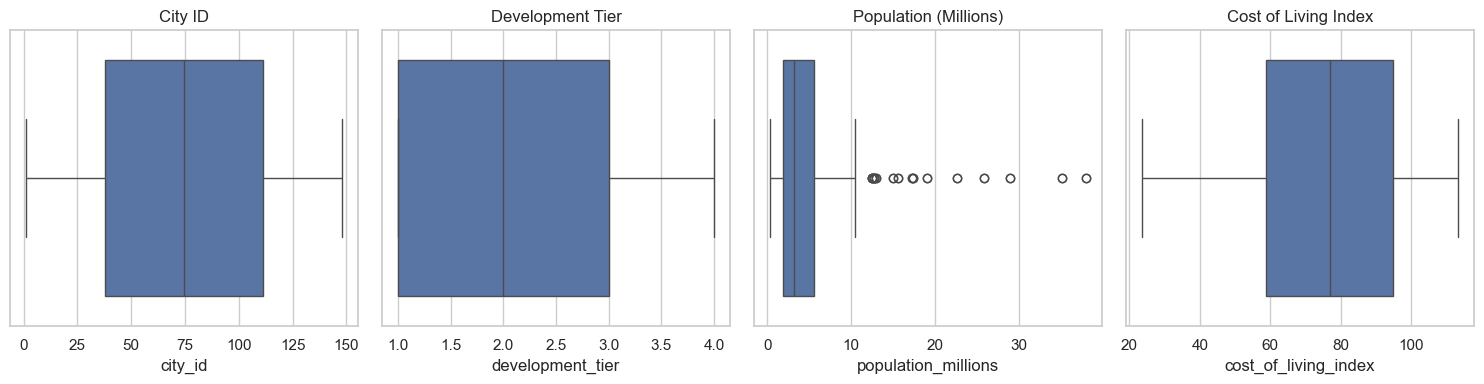

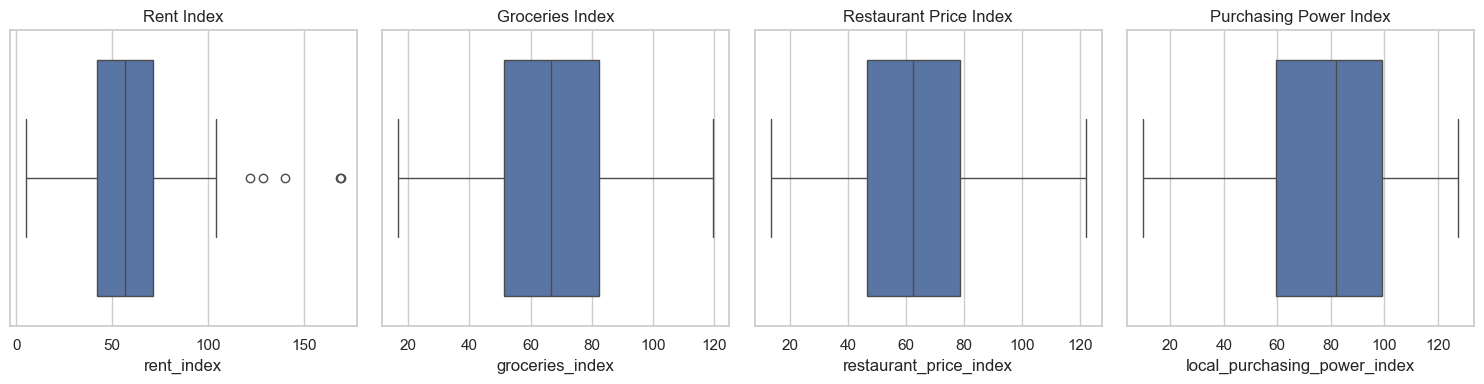

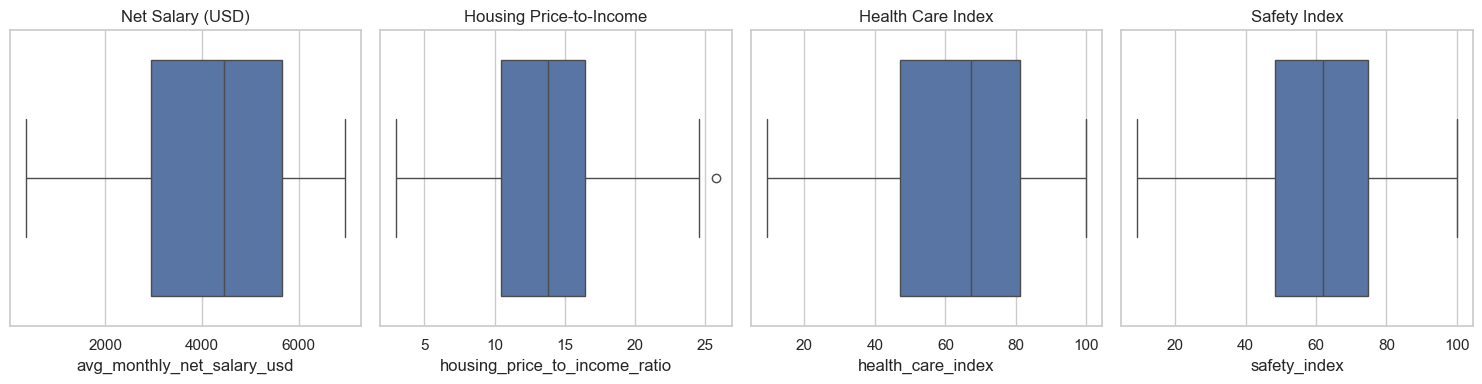

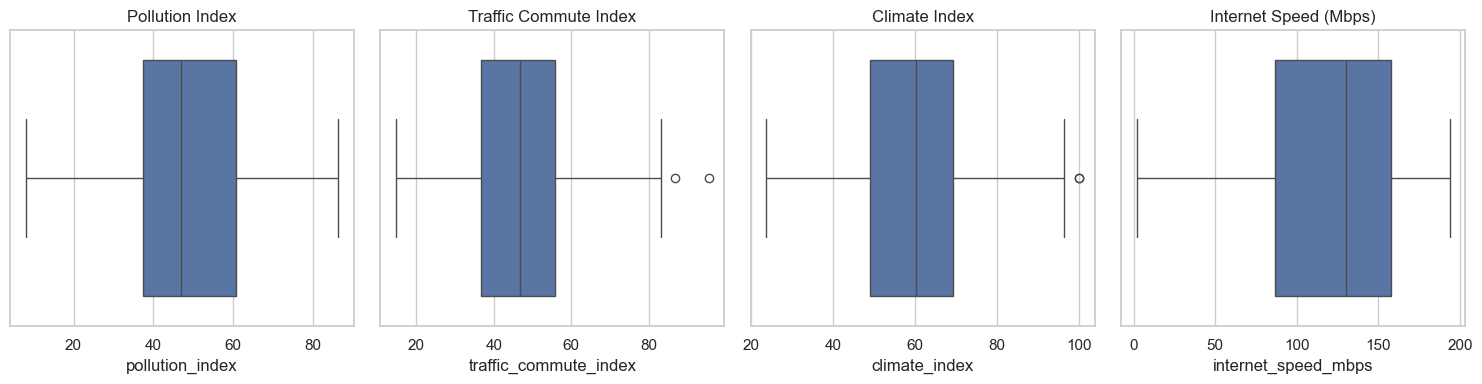

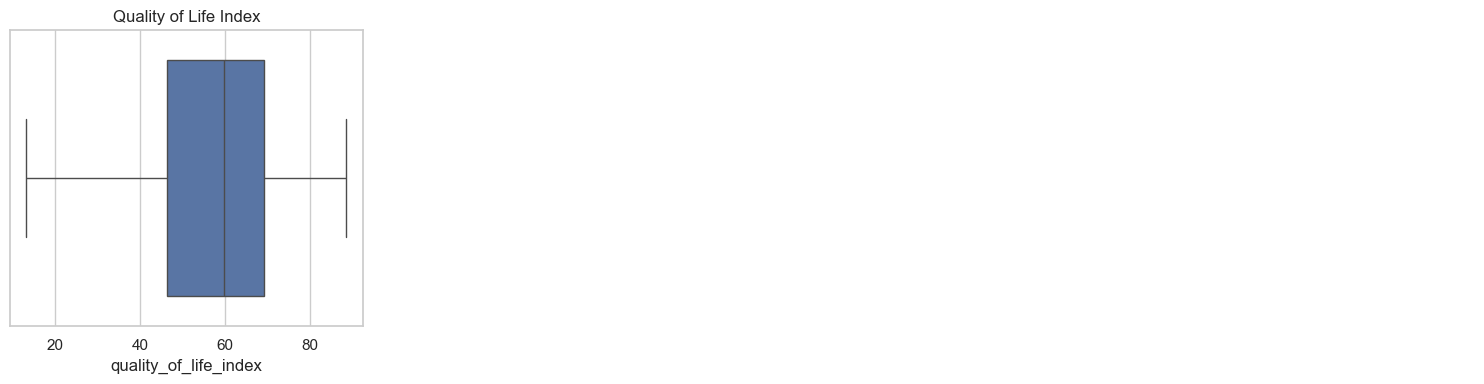

In [22]:
# inspect the distribution of the remaining numeric columns using boxplots to identify outliers and understand the spread of the data.

# Box -> Middle 50% of values
# Line inside the box ->	Median—the middle value
# Whiskers->Range defined by the boxplot rule
# Dots beyond the whiskers -> Potential outliers to investigate

# ==========================================
# ROW 1: Identifiers & Core Demographics
# ==========================================
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

sns.boxplot(x=df_clean["city_id"], ax=axes[0])
axes[0].set_title("City ID")

sns.boxplot(x=df_clean["development_tier"], ax=axes[1])
axes[1].set_title("Development Tier")

sns.boxplot(x=df_clean["population_millions"], ax=axes[2])
axes[2].set_title("Population (Millions)")

sns.boxplot(x=df_clean["cost_of_living_index"], ax=axes[3])
axes[3].set_title("Cost of Living Index")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_BoxPlots_Row1.png")
plt.show()


# ==========================================
# ROW 2: Economic & Cost Indices
# ==========================================
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

sns.boxplot(x=df_clean["rent_index"], ax=axes[0])
axes[0].set_title("Rent Index")

sns.boxplot(x=df_clean["groceries_index"], ax=axes[1])
axes[1].set_title("Groceries Index")

sns.boxplot(x=df_clean["restaurant_price_index"], ax=axes[2])
axes[2].set_title("Restaurant Price Index")

sns.boxplot(x=df_clean["local_purchasing_power_index"], ax=axes[3])
axes[3].set_title("Purchasing Power Index")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_BoxPlots_Row2.png")
plt.show()


# ==========================================
# ROW 3: Salaries, Housing & Healthcare
# ==========================================
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

sns.boxplot(x=df_clean["avg_monthly_net_salary_usd"], ax=axes[0])
axes[0].set_title("Net Salary (USD)")

sns.boxplot(x=df_clean["housing_price_to_income_ratio"], ax=axes[1])
axes[1].set_title("Housing Price-to-Income")

sns.boxplot(x=df_clean["health_care_index"], ax=axes[2])
axes[2].set_title("Health Care Index")

sns.boxplot(x=df_clean["safety_index"], ax=axes[3])
axes[3].set_title("Safety Index")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_BoxPlots_Row3.png")
plt.show()


# ==========================================
# ROW 4: Environment, Traffic & Connectivity
# ==========================================
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

sns.boxplot(x=df_clean["pollution_index"], ax=axes[0])
axes[0].set_title("Pollution Index")

sns.boxplot(x=df_clean["traffic_commute_index"], ax=axes[1])
axes[1].set_title("Traffic Commute Index")

sns.boxplot(x=df_clean["climate_index"], ax=axes[2])
axes[2].set_title("Climate Index")

sns.boxplot(x=df_clean["internet_speed_mbps"], ax=axes[3])
axes[3].set_title("Internet Speed (Mbps)")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_BoxPlots_Row4.png")
plt.show()


# ==========================================
# ROW 5: Target Variable (Quality of Life)
# ==========================================
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

sns.boxplot(x=df_clean["quality_of_life_index"], ax=axes[0])
axes[0].set_title("Quality of Life Index")

# Apagamos los ejes sobrantes de esta última fila para que no se vean vacíos feos
for i in range(1, 4):
    axes[i].axis('off')

plt.tight_layout()
plt.savefig(FIG_DIR / "01_BoxPlots_Row5.png")
plt.show()

In [23]:
# This block loops through quantitative fields and caps outliers

# Select only numeric columns
numeric_cols = df_clean.select_dtypes(include=['number']).columns

# Loop through each numeric column and cap outliers
for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

# Optional: Print the calculated boundaries for transparency
    print(f"Column '{col}' Bounds -> Lower: {lower_bound:.2f}, Upper: {upper_bound:.2f}")
    
    # Cap values outside the bounds
    df_clean[col] = df_clean[col].clip(lower=lower_bound, upper=upper_bound)


print (df_clean.head(10))

Column 'city_id' Bounds -> Lower: -72.50, Upper: 221.50
Column 'development_tier' Bounds -> Lower: -2.00, Upper: 6.00
Column 'population_millions' Bounds -> Lower: -3.56, Upper: 11.10
Column 'cost_of_living_index' Bounds -> Lower: 5.08, Upper: 148.47
Column 'rent_index' Bounds -> Lower: -2.09, Upper: 115.57
Column 'groceries_index' Bounds -> Lower: 4.59, Upper: 128.82
Column 'restaurant_price_index' Bounds -> Lower: -1.80, Upper: 126.58
Column 'local_purchasing_power_index' Bounds -> Lower: -0.51, Upper: 159.19
Column 'avg_monthly_net_salary_usd' Bounds -> Lower: -1125.61, Upper: 9724.76
Column 'housing_price_to_income_ratio' Bounds -> Lower: 1.42, Upper: 25.46
Column 'health_care_index' Bounds -> Lower: -3.58, Upper: 131.99
Column 'safety_index' Bounds -> Lower: 8.43, Upper: 114.52
Column 'pollution_index' Bounds -> Lower: 2.06, Upper: 96.05
Column 'traffic_commute_index' Bounds -> Lower: 8.01, Upper: 84.65
Column 'climate_index' Bounds -> Lower: 18.55, Upper: 99.52
Column 'internet_s

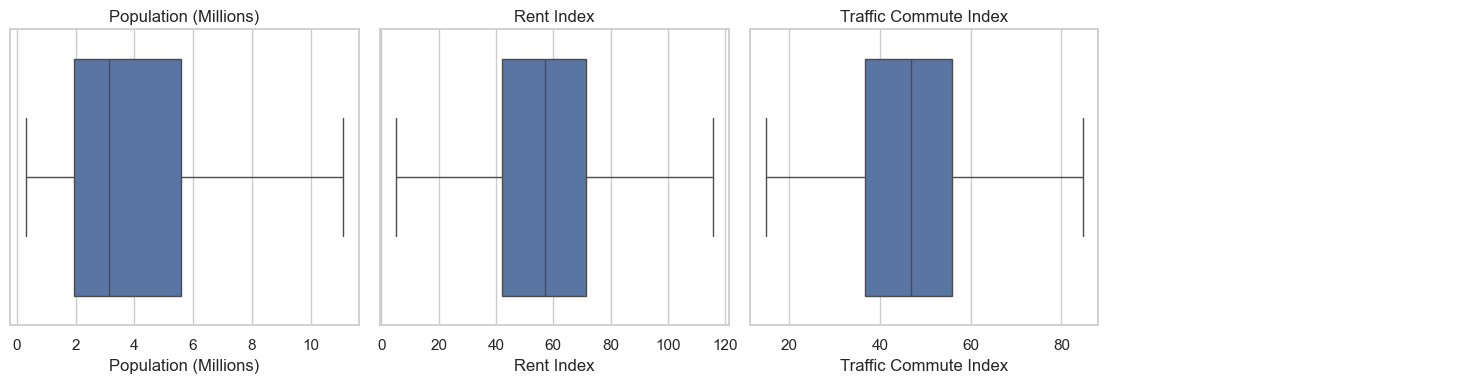

In [24]:
# Re-creating the box plots as before to demonstreate outlier capping:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

# 1. Population (Millions)
sns.boxplot(x=df_clean["population_millions"], ax=axes[0])
axes[0].set_title("Population (Millions)")
axes[0].set_xlabel("Population (Millions)")

# 2. Rent Index
sns.boxplot(x=df_clean["rent_index"], ax=axes[1])
axes[1].set_title("Rent Index")
axes[1].set_xlabel("Rent Index")

# 3. Traffic Commute Index
sns.boxplot(x=df_clean["traffic_commute_index"], ax=axes[2])
axes[2].set_title("Traffic Commute Index")
axes[2].set_xlabel("Traffic Commute Index")

# Turn off the 4th unused subplot to keep the layout clean
axes[3].axis('off')

plt.tight_layout()
plt.savefig(FIG_DIR / "01_BoxPlots_Affected_Columns.png")
plt.show()

In [25]:
# Initiating missing value analysis
missing_report(df_clean).head(12)

,n_missing,pct_missing
city_id,0,0.00
city,0,0.00
quality_of_life_index,0,0.00
internet_speed_mbps,0,0.00
climate_index,0,0.00
traffic_commute_index,0,0.00
pollution_index,0,0.00
safety_index,0,0.00
health_care_index,0,0.00
housing_price_to_income_ratio,0,0.00


In [26]:
# Check missing values before imputation
print("--- Missing values before imputation ---")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

# List of columns with missing values to impute
cols_to_impute = [
    'internet_speed_mbps', 
    'climate_index', 
    'traffic_commute_index', 
    'housing_price_to_income_ratio', 
    'avg_monthly_net_salary_usd'
]

# Fill missing values with the median of each column
for col in cols_to_impute:
    median_value = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_value)

# Verify that no missing values remain in the dataset
print("\n--- Missing values after imputation ---")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

--- Missing values before imputation ---
Series([], dtype: int64)

--- Missing values after imputation ---
Series([], dtype: int64)


# 4. **Feature Engineering**     
Steps:     
    a. Extract **temporal features** (If necessary)  
    b. **Create** more features depending on the **relation between existing features**.              
    c. Format or transform variables to ensure they are fully model-ready 

In [27]:
# Feature Engineering
# 1. Temporal Features: Extract survey year from survey_date
df_clean['survey_year'] = pd.to_datetime(df_clean['survey_date']).dt.year

# 2. Economic Ratios & Indicators:
# Combine groceries and restaurant indices to measure total food cost pressure
df_clean['food_cost_index'] = (df_clean['groceries_index'] + df_clean['restaurant_price_index']) / 2

# Measure purchasing power relative to cost of living (proxy for disposable income adjustment)
df_clean['disposable_income_proxy'] = df_clean['avg_monthly_net_salary_usd'] / (df_clean['cost_of_living_index'] + 1)

# Rent to income or living relationship metric
df_clean['rent_to_living_ratio'] = df_clean['rent_index'] / (df_clean['cost_of_living_index'] + 1)

# Display the first few rows with the newly created features
display(df_clean[['city', 'survey_year', 'food_cost_index', 'disposable_income_proxy', 'rent_to_living_ratio']].head())

,city,survey_year,food_cost_index,disposable_income_proxy,rent_to_living_ratio
0,Abidjan,2023,44.84,37.27,0.54
1,Abidjan,2024,47.14,34.78,0.50
2,Abu Dhabi,2023,75.33,59.57,0.60
3,Abu Dhabi,2024,91.66,65.84,0.81
4,Abuja,2023,34.58,45.73,0.69


# 5. Comparing raw and clean datasets

In [28]:
# Before / after comparison
comparison = pd.DataFrame(
    {
        "raw": [
            len(df),
            df.shape[1],
            df.select_dtypes("number").shape[1],
            df.isna().mean().mean() * 100,
            df.memory_usage(deep=True).sum() / 1e6,
        ],
        "clean": [
            len(df_clean),
            df_clean.shape[1],
            df_clean.select_dtypes("number").shape[1],
            df_clean.isna().mean().mean() * 100,
            df_clean.memory_usage(deep=True).sum() / 1e6,
        ],
    },
    index=["rows", "columns", "numeric columns", "average % missing", "memory (MB)"],
)
comparison

,raw,clean
rows,296.00,296.00
columns,26.00,28.00
numeric columns,17.00,21.00
average % missing,3.22,0.00
memory (MB),0.20,0.15


# 6. **(EDA)** 
Exploring the data with **descriptive statistics** and **visualizations** (matplotlib + seaborn).

Steps:      
    a.  **Univariate**: one variable at a time    
    b.  **Bivariate**: two variables together       
    c. **Multivariate**: several variables at once    
        - Correlation

In [29]:
key_numeric = df_clean.select_dtypes(include="number").columns.tolist()
key_numeric

stats = df_clean[key_numeric].describe().T

stats["skewness"] = df_clean[key_numeric].skew()
stats

,count,mean,std,min,25%,50%,75%,max,skewness
city_id,296.00,74.50,42.80,1.00,37.75,74.50,111.25,148.00,0.00
development_tier,296.00,2.26,1.13,1.00,1.00,2.00,3.00,4.00,0.22
population_millions,296.00,4.21,3.14,0.31,1.94,3.13,5.60,11.10,1.06
cost_of_living_index,296.00,75.16,22.31,23.54,58.85,76.97,94.70,113.29,-0.43
rent_index,296.00,57.61,21.33,5.02,42.03,56.93,71.44,115.57,0.25
groceries_index,296.00,65.30,20.89,16.79,51.17,66.70,82.23,119.62,-0.19
restaurant_price_index,296.00,62.07,21.83,13.30,46.34,62.34,78.44,121.85,0.17
local_purchasing_power_index,296.00,78.71,26.25,9.89,59.38,81.91,99.31,127.65,-0.33
avg_monthly_net_salary_usd,296.00,"4,227.17","1,582.97",359.07,"2,943.28","4,454.21","5,655.87","6,967.19",-0.39
housing_price_to_income_ratio,296.00,13.54,4.28,3.00,10.44,13.79,16.45,25.46,0.06


### a. Univariate analysis

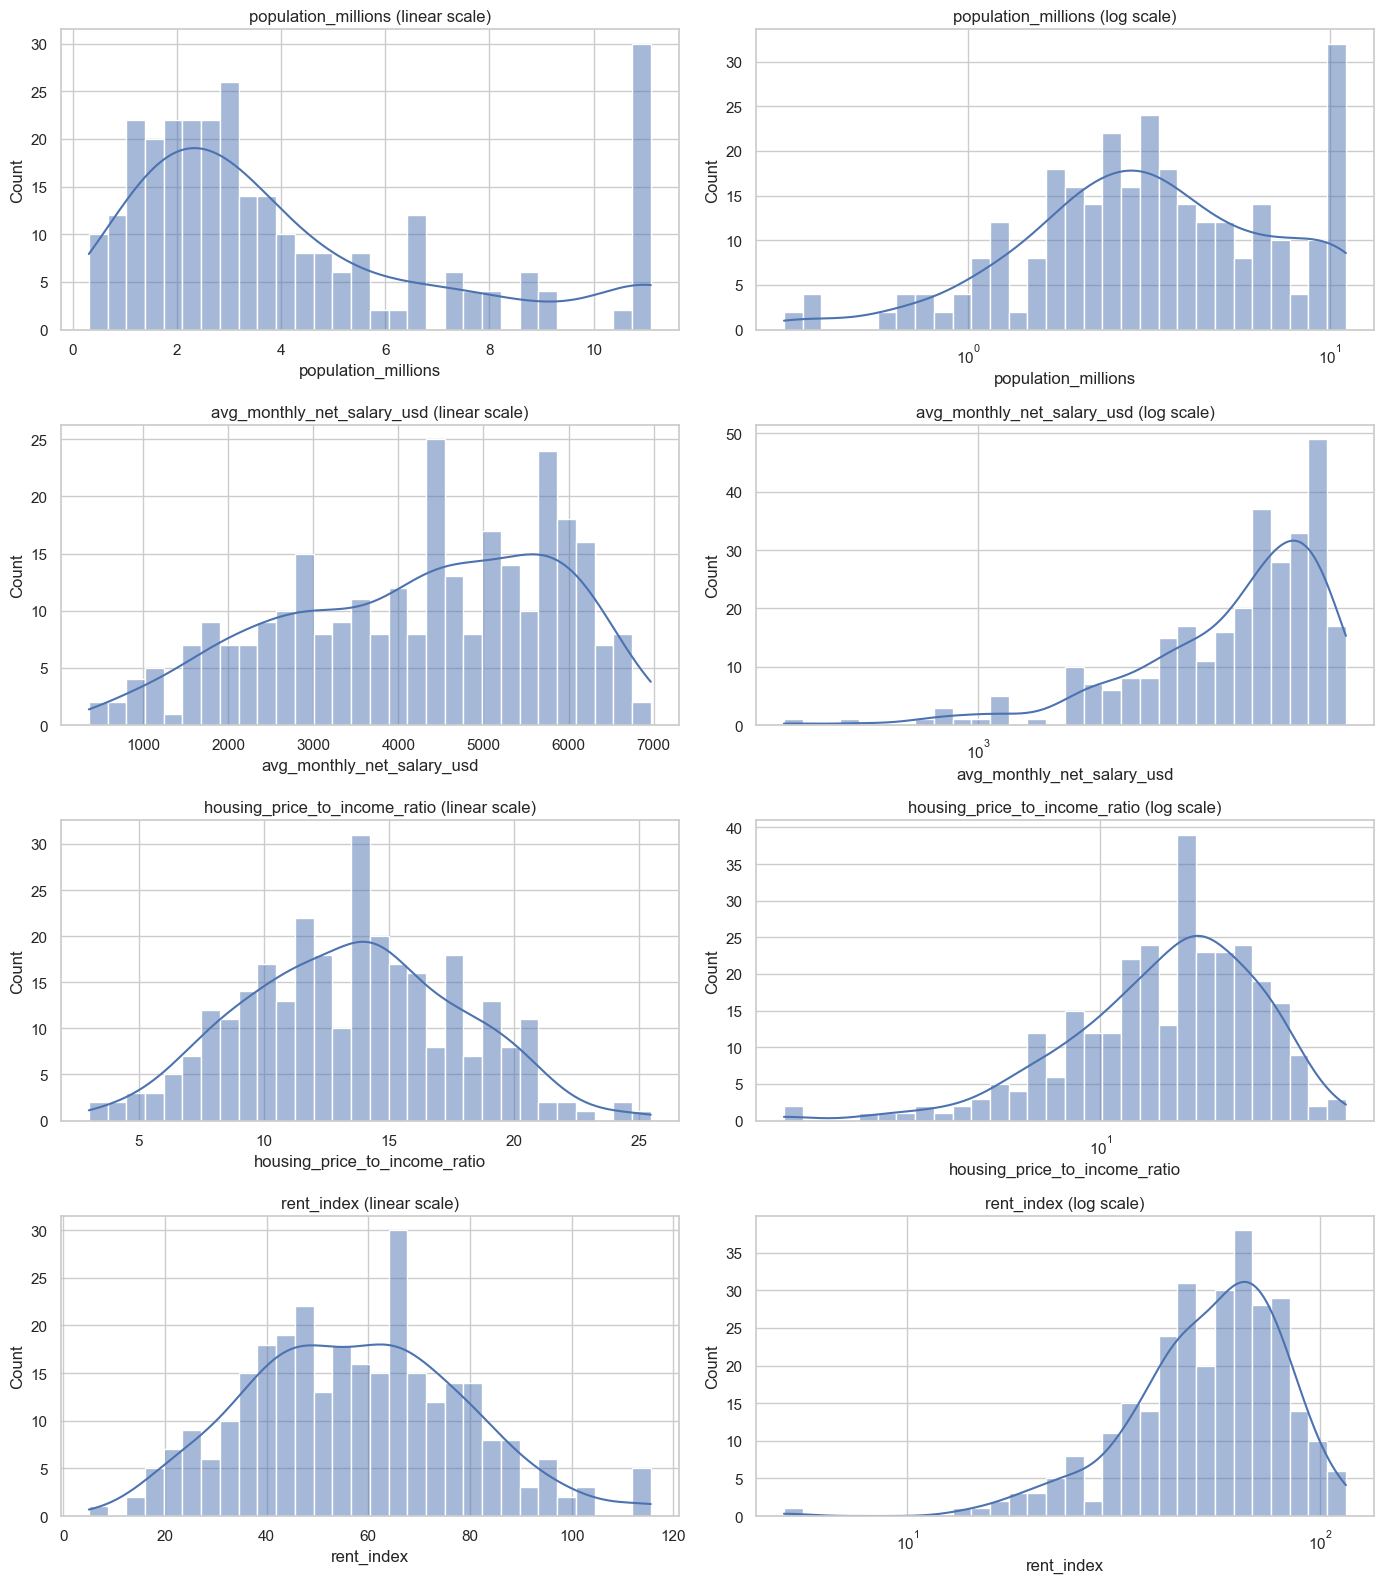

In [30]:
log_cols = ["population_millions", "avg_monthly_net_salary_usd",
            "housing_price_to_income_ratio", "rent_index"]

fig, axes = plt.subplots(len(log_cols), 2, figsize=(14, 4 * len(log_cols)), squeeze=False)

for i, col in enumerate(log_cols):
    data = df_clean[col].dropna()          # remove NaN first

    sns.histplot(data, bins=30, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} (linear scale)")

    if (data > 0).all():
        sns.histplot(data, bins=30, kde=True, log_scale=True, ax=axes[i, 1])
        axes[i, 1].set_title(f"{col} (log scale)")
    else:
        axes[i, 1].set_title(f"{col} (log scale not possible)")
        axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

Skewed behavior in linear scale:     
Financial and demographic variables such as population_millions, avg_monthly_net_salary_usd, housing_price_to_income_ratio, and rent_index show distributions strongly skewed to the right in their linear scale, characterized by long tails formed by a few global cities with extremely high values.

Effect of logarithmic transformation: By applying the logarithmic scale, the distributions are visually compressed, normalized, becoming much more symmetrical and mitigating the impact of extreme values, facilitating the performance of Machine Learning algorithms


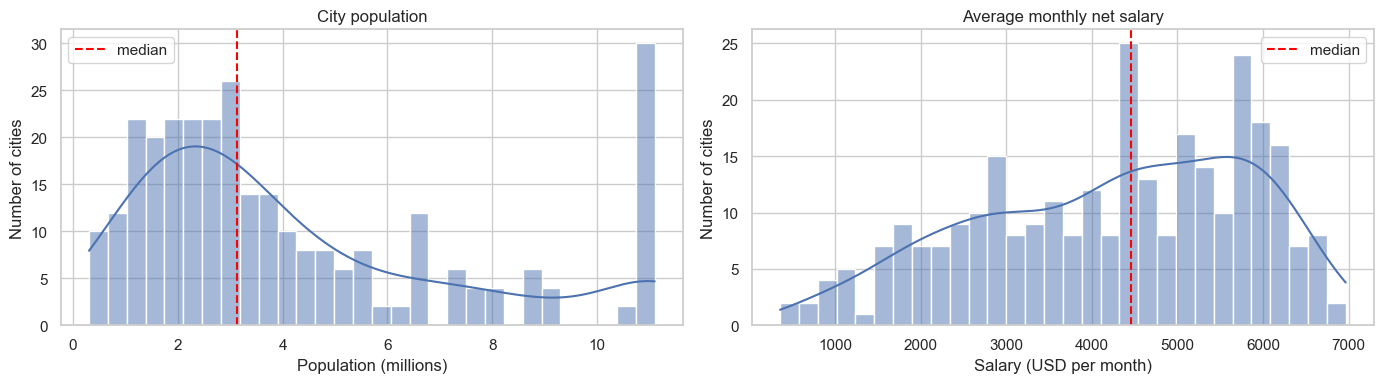

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: city size
pop = df_clean["population_millions"].dropna()
sns.histplot(pop, bins=30, kde=True, ax=axes[0])
axes[0].axvline(pop.median(), color="red", linestyle="--", label="median")
axes[0].set_title("City population")
axes[0].set_xlabel("Population (millions)")
axes[0].set_ylabel("Number of cities")
axes[0].legend()

# Right: income
sal = df_clean["avg_monthly_net_salary_usd"].dropna()
sns.histplot(sal, bins=30, kde=True, ax=axes[1])
axes[1].axvline(sal.median(), color="red", linestyle="--", label="median")
axes[1].set_title("Average monthly net salary")
axes[1].set_xlabel("Salary (USD per month)")
axes[1].set_ylabel("Number of cities")
axes[1].legend()

plt.tight_layout()
plt.show()

The left chart we can also remove it     

Concentration in low and medium ranges:     
The histogram with the vertical median line clearly show that the vast majority of cities in the dataset are concentrated in the lower and moderate levels of average monthly salary.

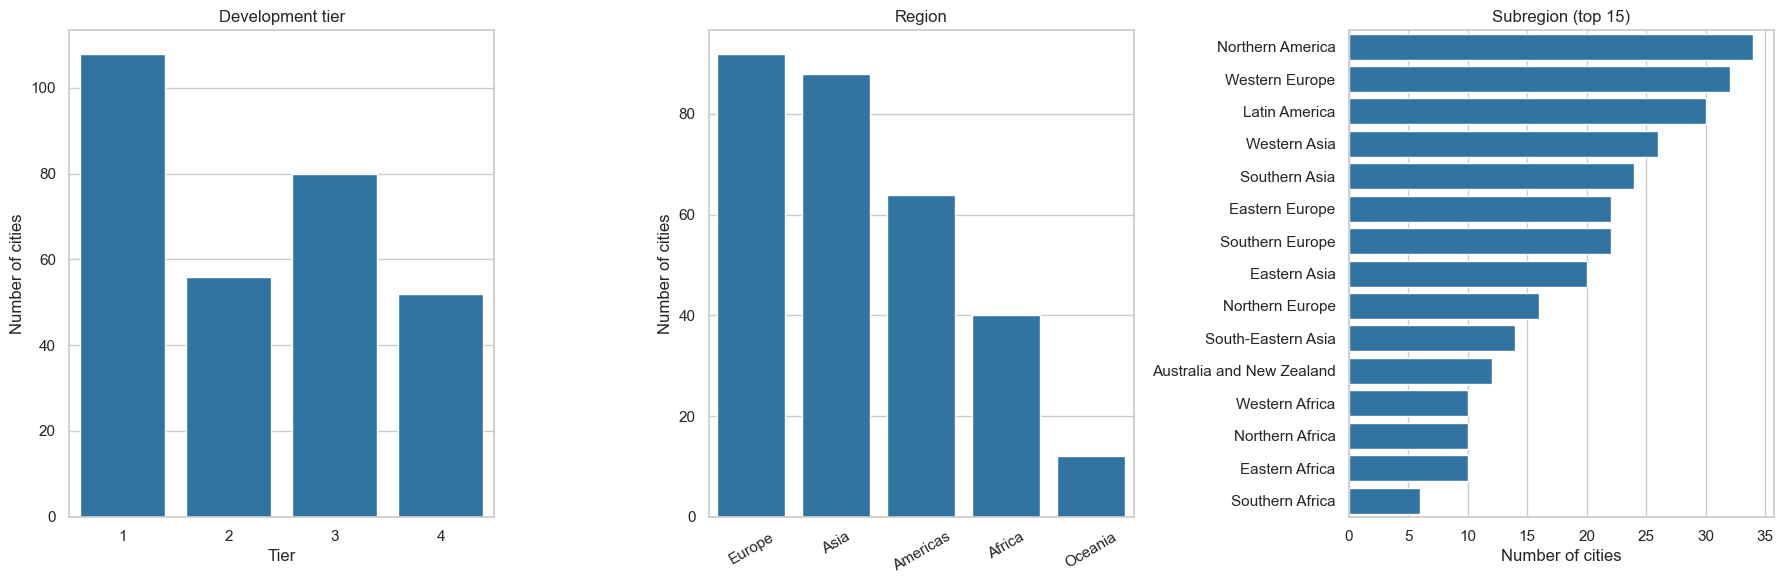

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Ordered category: keep natural order
sns.countplot(data=df_clean, x="development_tier", color="tab:blue", ax=axes[0])
axes[0].set_title("Development tier")
axes[0].set_xlabel("Tier")
axes[0].set_ylabel("Number of cities")

# Sorted by frequency
sns.countplot(data=df_clean, x="region",
              order=df_clean["region"].value_counts().index,
              color="tab:blue", ax=axes[1])
axes[1].set_title("Region")
axes[1].set_xlabel("")
axes[1].set_ylabel("Number of cities")
axes[1].tick_params(axis="x", rotation=30)

# Horizontal bars, top 15
top_subregions = df_clean["subregion"].value_counts().head(15).index
sns.countplot(data=df_clean, y="subregion", order=top_subregions,
              color="tab:blue", ax=axes[2])
axes[2].set_title("Subregion (top 15)")
axes[2].set_ylabel("")
axes[2].set_xlabel("Number of cities")

plt.tight_layout()
plt.show()

Distribution by development tiers (development_tier): It shows how cities are divided according to their socio-economic development category, allowing us to see if the dataset is balanced or if a particular category predominates.
      
Geographical representation (region and subregion): Frequency-sorted bar charts reveal which global regions and subregions (top 15) have the strongest presence in the study.            
         
Analytical implication: This overview ensures that we understand the demographic and geographic composition of the dataset, avoiding hidden regional biases before moving on to predictive modeling.            

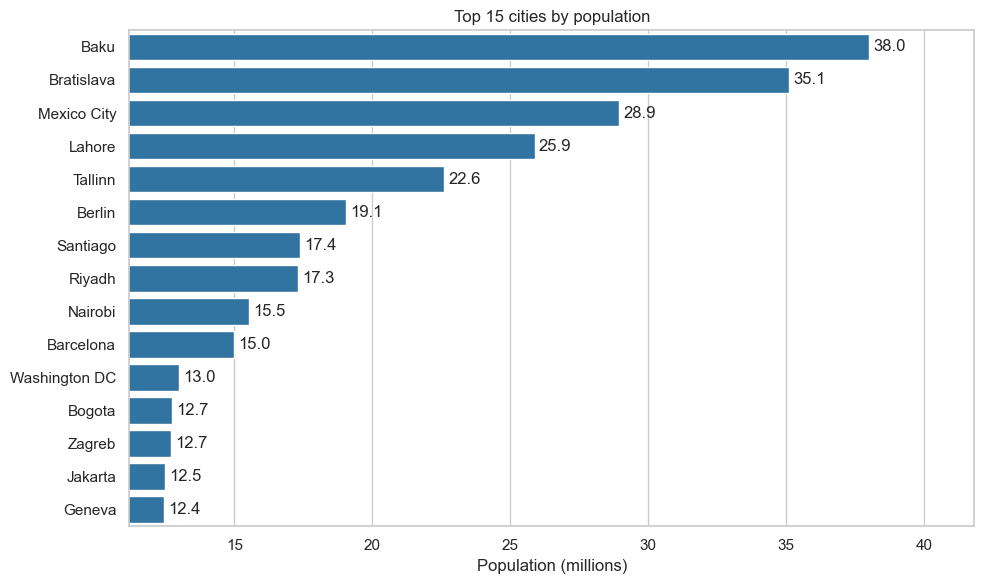

The top 15 cities hold 39% of the total population in this dataset


In [33]:
metric = "population_millions"

cities = (df.drop_duplicates(subset=["city", "country"])
            .set_index("city")[metric])
top_cities = cities.nlargest(15)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_cities.values, y=top_cities.index, color="tab:blue", ax=ax)
ax.set_xlim(left=top_cities.min() * 0.9, right=top_cities.max() * 1.1)
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.set_title("Top 15 cities by population")
ax.set_xlabel("Population (millions)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

share = top_cities.sum() / cities.sum()
print(f"The top 15 cities hold {share:.0%} of the total population in this dataset")

### I think we can delete this graphic (and the code) cause we notice that the population numbers are wrong

### b. Bivariate analysis

C:\Users\diego\AppData\Local\Temp\ipykernel_34448\3735446459.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.nlargest(5, "avg_monthly_net_salary_usd")))


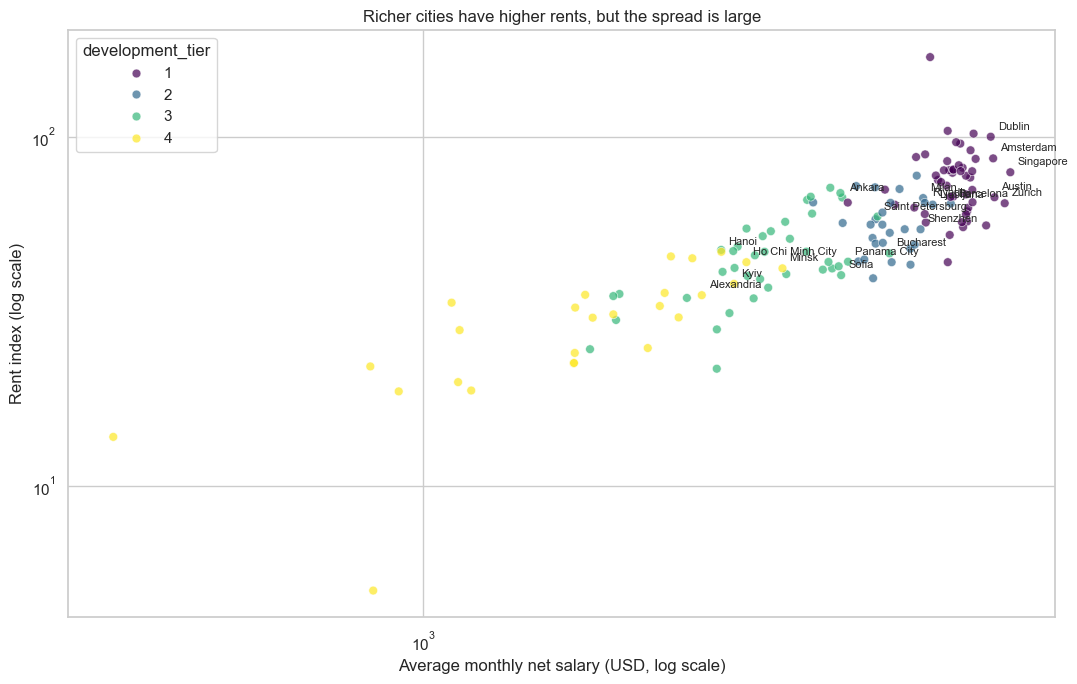

In [34]:
# One row per city, no missing values in the plotted columns
plot_df = (df.drop_duplicates(subset=["city", "country"])
             .dropna(subset=["avg_monthly_net_salary_usd", "rent_index"]))

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=plot_df, x="avg_monthly_net_salary_usd", y="rent_index",
                hue="development_tier", palette="viridis",
                alpha=0.7, s=40, ax=ax)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Richer cities have higher rents, but the spread is large")
ax.set_xlabel("Average monthly net salary (USD, log scale)")
ax.set_ylabel("Rent index (log scale)")

# Label the five highest-paid cities in EACH development tier
labels = (plot_df.groupby("development_tier", group_keys=False)
                 .apply(lambda g: g.nlargest(5, "avg_monthly_net_salary_usd")))

for _, r in labels.iterrows():
    ax.annotate(r["city"], (r["avg_monthly_net_salary_usd"], r["rent_index"]),
                xytext=(5, 5), textcoords="offset points", fontsize=8)

plt.tight_layout()
# save_fig("03_salary_vs_rent")   # uncomment to save
plt.show()

Bivariate Analysis Conclusion: Salary vs. Rent Index        
Direct Relationship (Positive Correlation): There is a clear positive relationship between a city's economic power and its housing costs. As expected, cities with higher average monthly net salaries tend to exhibit significantly higher rent indices.

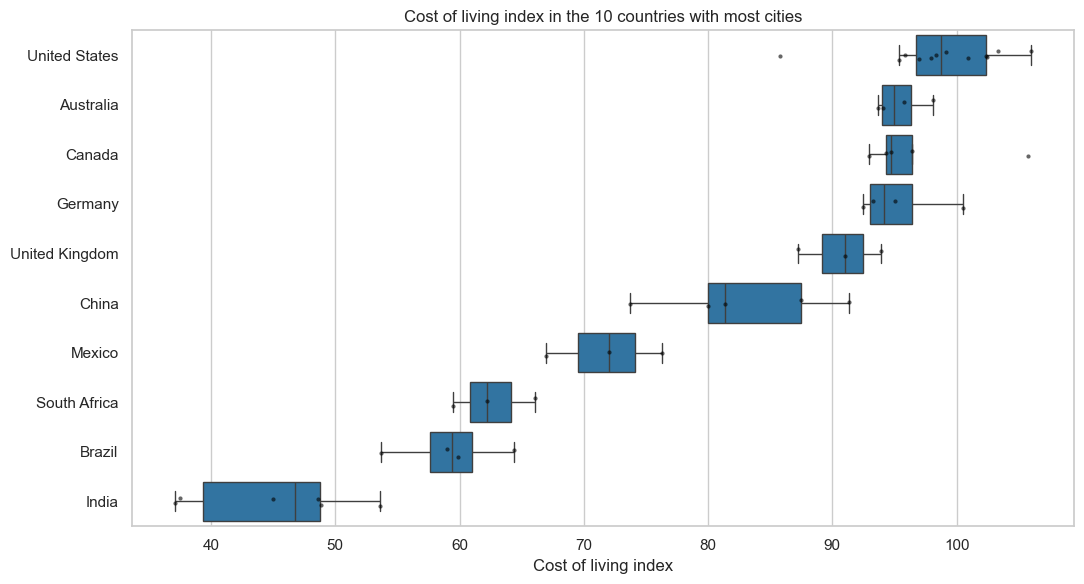

In [35]:
cities = df.drop_duplicates(subset=["city", "country"])

top10_countries = cities["country"].value_counts().head(10).index
in_top10 = cities[cities["country"].isin(top10_countries)]

metric = "cost_of_living_index"   # or rent_index, groceries_index, restaurant_price_index

country_order = (in_top10.groupby("country")[metric]
                         .median().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=in_top10, x=metric, y="country", order=country_order,
            showfliers=False, color="tab:blue", ax=ax)
sns.stripplot(data=in_top10, x=metric, y="country", order=country_order,
              color="black", size=3, alpha=0.6, ax=ax)
ax.set_title("Cost of living index in the 10 countries with most cities")
ax.set_xlabel("Cost of living index")
ax.set_ylabel("")
plt.tight_layout()
# save_fig("04_cost_of_living_by_country")
plt.show()

There is a clear structural separation between developed economies (United States, Australia, Canada, Germany, and the United Kingdom) and emerging markets. Developed nations cluster at the top with median cost-of-living indices ranging significantly higher (mostly between 85 and 100).

### -Correlation


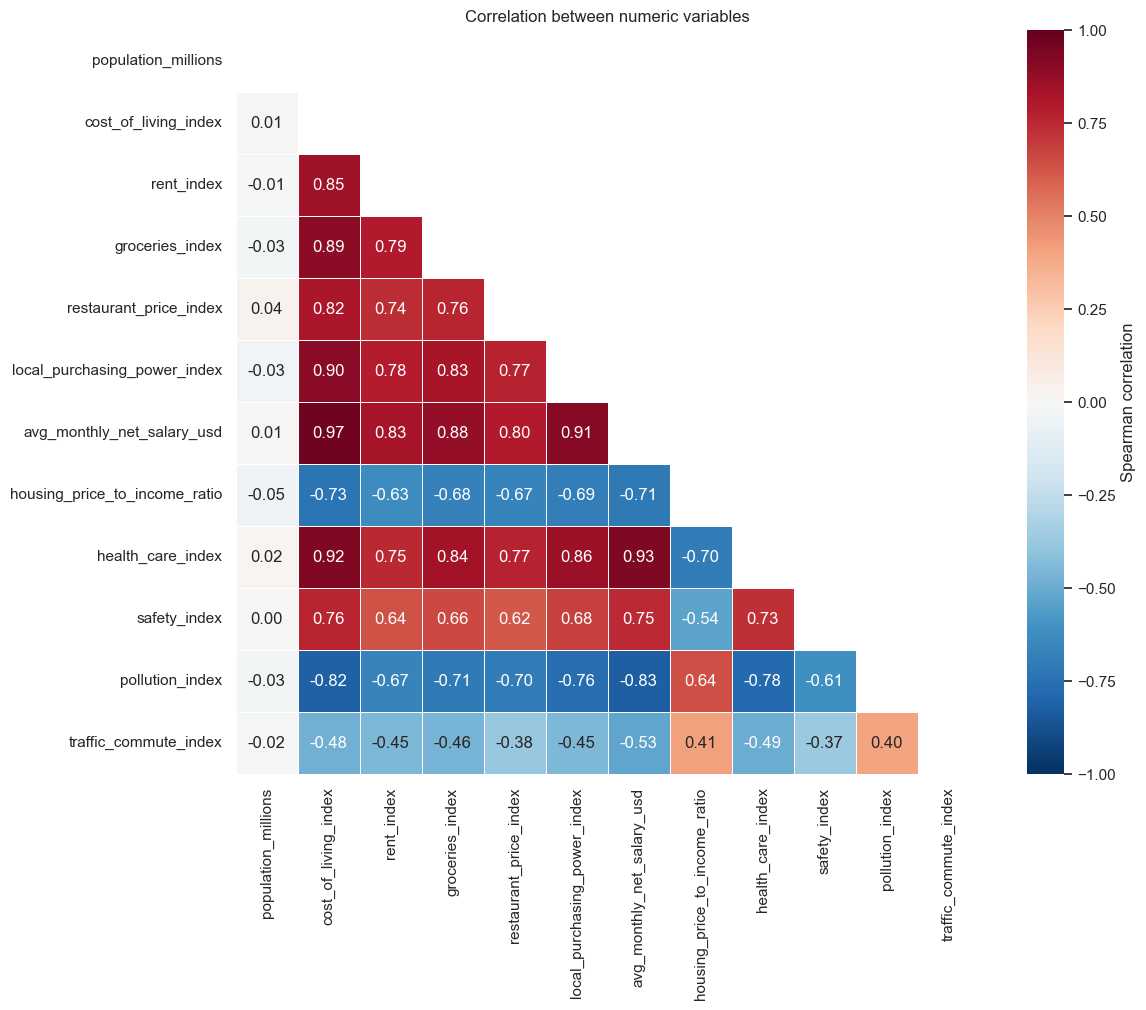

avg_monthly_net_salary_usd       0.97
health_care_index                0.92
local_purchasing_power_index     0.90
groceries_index                  0.89
rent_index                       0.85
restaurant_price_index           0.82
safety_index                     0.76
population_millions              0.01
traffic_commute_index           -0.48
housing_price_to_income_ratio   -0.73
pollution_index                 -0.82
Name: cost_of_living_index, dtype: float64

In [36]:
cities = df.drop_duplicates(subset=["city", "country"])

corr_columns = [
    "population_millions", "cost_of_living_index", "rent_index", "groceries_index",
    "restaurant_price_index", "local_purchasing_power_index", "avg_monthly_net_salary_usd",
    "housing_price_to_income_ratio", "health_care_index", "safety_index",
    "pollution_index", "traffic_commute_index",
]
corr = cities[corr_columns].corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.grid(False)
ax.set_title("Correlation between numeric variables")
plt.tight_layout()
# save_fig("07_correlation_heatmap")
plt.show()

# Correlations with one target, sorted
target = "cost_of_living_index"
corr[target].drop(target).sort_values(ascending=False)

Strong Economic Core: There is an exceptionally high positive correlation between the **cost of living index** and the **average monthly net salary** ($0.97$), confirming that wealthier cities structurally scale their living expenses alongside income levels.

Quality & Purchasing Clusters: Key quality metrics such as **health care index** ($0.92$) and **local purchasing power** ($0.90$) move in tandem with economic wealth, showing that higher-tier cities bundle multiple advantages together.

Notable Inverse Relationships: The **pollution index** shows a strong negative correlation with both **net salary** ($-0.83$) and **cost of living** ($-0.82$), suggesting that higher-income cities in this dataset generally report lower pollution burdens. Similarly, the **housing price-to-income ratio** exhibits inverse trends against **absolute salary levels** ($-0.71$).

### c. Multivariate analysis

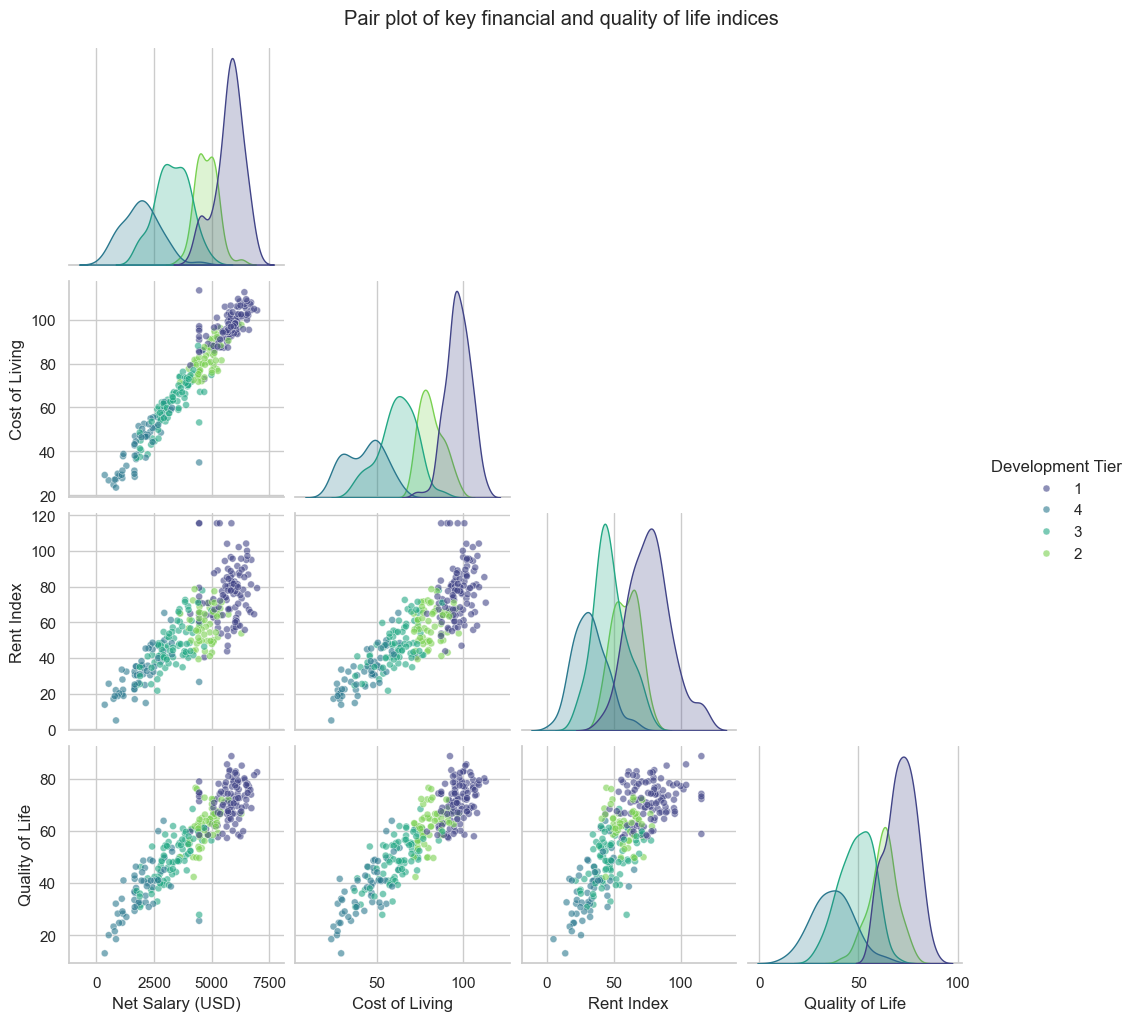

In [38]:
# Sample 2,000 rows (or the full dataset if smaller, since we have 296 rows) 
# and select key numerical variables alongside our development tier category
pair_data = df_clean.dropna(subset=["quality_of_life_index"]).copy()

# If your dataset has fewer than 2000 rows, use all available rows safely:
sample_size = min(2000, len(pair_data))
pair_data = pair_data.sample(sample_size, random_state=42)

# Construct a DataFrame with the chosen key variables
pair_df = pd.DataFrame({
    "Net Salary (USD)": pair_data["avg_monthly_net_salary_usd"],
    "Cost of Living": pair_data["cost_of_living_index"],
    "Rent Index": pair_data["rent_index"],
    "Quality of Life": pair_data["quality_of_life_index"],
    "Development Tier": pair_data["development_tier"].astype(str), # Categorical hue
})

# Generate the pairplot with the lower half (corner=True) for clean visualization
grid = sns.pairplot(
    pair_df, 
    hue="Development Tier", 
    corner=True, 
    plot_kws={"alpha": 0.6, "s": 25},
    palette="viridis"
)
grid.figure.suptitle("Pair plot of key financial and quality of life indices", y=1.02)
plt.show()

### **Multivariate Pair Plot Conclusion**
* **Non-Linear Interactions:** The pairwise subplots reveal clear multi-variable clustering, especially between financial indicators (`Net Salary` vs. `Cost of Living` and `Rent Index`), where advanced development tiers form dense groupings in the upper spectrum.         
       
* **Diagonal Distributions:** The univariate histograms along the diagonal confirm the spread of each individual index, showing distinct skewness patterns that validate our earlier log-transformation and scaling strategies.          
                 
* **Target Separability:** The distribution of the `Quality of Life` target variable across different development tiers shows progressive stratification, indicating that these features will serve as strong predictors for our upcoming Machine Learning models in Day 2.